# End-functionalized Homopolymer Plots

This notebook develops the partition coefficient for a linear homopolymer with one or two adsorption-active ends. The ordinary chain calculation is reused as $K^{(0)}$, while equations (3), (4), (9), and (10) add the contribution of one or both functional ends.

The work has three stages:

1. Calculate the ordinary homopolymer partition coefficient $K^{(0)}$.
2. Calculate the one-end and two-end contact probabilities $U_1$ and $U_2$.
3. Add the end-group corrections and investigate how $K$ changes with pore size, chain length, and interaction strength.

## What the symbols mean

- $R_G$: radius of gyration, which estimates the polymer's size in space.
- $R_P$: pore radius or characteristic pore size.
- $g=R_G/R_P$: dimensionless polymer-to-pore size ratio.
- $\lambda$: polymer-wall interaction parameter. In this paper, positive values represent repulsion and negative values represent attraction for the ordinary chain units.
- $q_a$, $q_b$: reduced interaction parameters for the functional end groups.
- $p_a=U_1$: probability associated with functional group $a$ contacting the pore wall.
- $p_b=U_1$: the same one-end probability for a second identical functional group.
- $p_{ab}=U_2$: probability associated with both functional ends being in contact with the pore walls.
- $N$: number of repeat units in the chain.

In [1]:
import math
import matplotlib.pyplot as plt

## Finding the characteristic roots

The equations contain $\alpha_k$, but its value cannot be isolated by simple algebra. It is found by solving

$$\alpha_k=\tan^{-1}\left(\frac{\lambda}{\alpha_k}\right)+\frac{(k-1)\pi}{2}.$$

This notebook uses bisection. Bisection starts with an interval known to contain a root and repeatedly divides it in half. When the interval becomes smaller than `1e-12`, the midpoint is treated as a sufficiently accurate answer.

In [ ]:
def bisect(function, lower, upper, tolerance=1e-12):
    """Find a root where function(lower) and function(upper) have opposite signs."""
    lower_value = function(lower)
    upper_value = function(upper)

    if lower_value * upper_value > 0:
        raise ValueError("The root is not bracketed.")

    while upper - lower > tolerance:
        middle = (lower + upper) / 2
        middle_value = function(middle)

        if lower_value * middle_value <= 0:
            upper, upper_value = middle, middle_value
        else:
            lower, lower_value = middle, middle_value

    return (lower + upper) / 2

In [ ]:
def root_squared(lambda_value, odd_m):
    """Return alpha_m squared for one odd characteristic mode."""
    if lambda_value == 0:
        base = (odd_m - 1) * math.pi / 2
        return base * base

    if odd_m == 1 and lambda_value < 0:
        beta = bisect(
            lambda beta: beta * math.tanh(beta) + lambda_value,
            1e-12,
            math.sqrt(-lambda_value) + 2,
        )
        return -(beta * beta)

    base = (odd_m - 1) * math.pi / 2

    if lambda_value > 0:
        lower = base + 1e-10
        upper = base + math.pi / 2 - 1e-10
    else:
        lower = base - math.pi / 2 + 1e-10
        upper = base - 1e-10

    def characteristic_root(alpha):
        return alpha - base - math.atan(lambda_value / alpha)

    alpha = bisect(characteristic_root, lower, upper)
    return alpha * alpha

## Ordinary homopolymer function

This function implements the ordinary homopolymer result. For every odd characteristic mode, it calculates one term, multiplies it by an exponential decay factor, and adds all terms together.

At $\lambda=0$, the notebook uses the limiting result $K=1$. For positive and negative $\lambda$, it uses the characteristic roots and sums the modes.

In [ ]:
def K_homopolymer(g, lambda_value, terms=101):
    """Calculate the ordinary homopolymer partition coefficient K(0)."""
    if lambda_value == 0:
        return 1.0

    total = 0.0
    for odd_m in range(1, terms + 1, 2):
        alpha_squared = root_squared(lambda_value, odd_m)
        denominator = alpha_squared * (
            lambda_value * lambda_value + alpha_squared + lambda_value
        )
        term = 2 * lambda_value * lambda_value / denominator
        total += term * math.exp(-alpha_squared * g * g)
    return total

## End-contact probabilities

The paper distinguishes two kinds of end-contact information.

### One-end probability: $U_1$

Equation (9) is

$$p_a=U_1(\lambda,g)=\sum_{k\ \text{odd}}\frac{2\lambda}{\lambda+\lambda^2+\alpha_k^2}e^{-\alpha_k^2g^2}.$$

$U_1$ describes how strongly one functional end can interact with the pore wall.

### Two-end probability: $U_2$

Equation (10) is

$$p_{ab}=U_2(\lambda,g)=\sum_{k\ \text{odd}}\frac{2\alpha_k^2}{\lambda+\lambda^2+\alpha_k^2}e^{-\alpha_k^2g^2}.$$

$U_2$ describes the additional probability associated with both ends participating in contacts. It supplies the cross term used in the double-functionalized equation.

In [9]:
def U1(lambda_value, g, terms=101):
    """One-end contact probability from Eq. 9."""
    if lambda_value == 0:
        return 0.0

    total = 0.0
    for odd_m in range(1, terms + 1, 2):
        alpha_squared = root_squared(lambda_value, odd_m)
        denominator = lambda_value + lambda_value * lambda_value + alpha_squared
        total += (2 * lambda_value / denominator) * math.exp(-alpha_squared * g * g)
    return total


def U2(lambda_value, g, terms=101):
    """Two-end contact probability from Eq. 10."""
    if lambda_value == 0:
        # In the lambda=0 limit, A_1=2. The remaining odd modes follow Eq. 10.
        total = 2.0
        odd_modes = range(3, terms + 1, 2)
    else:
        total = 0.0
        odd_modes = range(1, terms + 1, 2)

    for odd_m in odd_modes:
        alpha_squared = root_squared(lambda_value, odd_m)
        denominator = lambda_value + lambda_value * lambda_value + alpha_squared
        total += (2 * alpha_squared / denominator) * math.exp(-alpha_squared * g * g)
    return total

## Equations (3) and (4)

### One functional end: Eq. (3)

$$K^{(1)}=K^{(0)}+q_a p_a.$$

This means the functional end adds or removes partitioning through $q_a$, while $p_a$ gives the probability for that end to interact with the pore wall.

### Two functional ends: Eq. (4)

For two groups:

$$K^{(2)}=K^{(0)}+q_a p_a+q_b p_b+q_aq_b p_{ab}.$$

The first correction describes end $a$, the second describes end $b$, and the final $q_aq_bp_{ab}$ term is a cross term: it becomes important when both ends participate simultaneously.

When the two ends are identical, `q_a = q_b = q` and `p_a = p_b = U1`. The function can therefore investigate one-end and two-end effects while keeping the ordinary-chain result unchanged.

In [10]:
def K_singly_functionalized(g, lambda_value, q_a, terms=101):
    """Calculate one end-functionalized K using Eq. 3."""
    return K_homopolymer(g, lambda_value, terms) + q_a * U1(lambda_value, g, terms)


def K_doubly_functionalized(g, lambda_value, q_a, q_b, terms=101):
    """Calculate two end-functionalized K using Eq. 4."""
    p_a = U1(lambda_value, g, terms)
    p_b = p_a
    p_ab = U2(lambda_value, g, terms)
    return (
        K_homopolymer(g, lambda_value, terms)
        + q_a * p_a
        + q_b * p_b
        + q_a * q_b * p_ab
    )

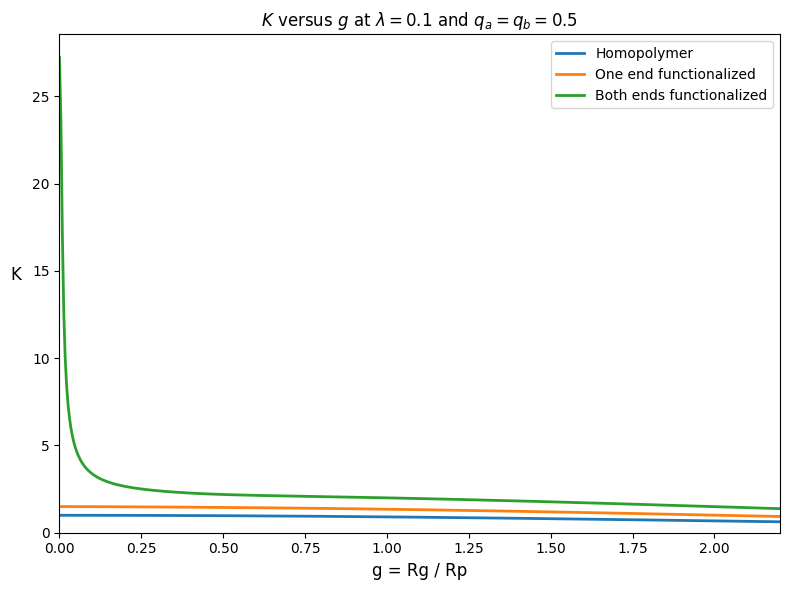

In [11]:
g_values = [index * 2.2 / 500 for index in range(501)]
lambda_value = 0.1
q_a = 0.5
q_b = 0.5

homopolymer = [K_homopolymer(g, lambda_value) for g in g_values]
single = [K_singly_functionalized(g, lambda_value, q_a) for g in g_values]
double = [K_doubly_functionalized(g, lambda_value, q_a, q_b) for g in g_values]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(g_values, homopolymer, label="Homopolymer", linewidth=2)
ax.plot(g_values, single, label="One end functionalized", linewidth=2)
ax.plot(g_values, double, label="Both ends functionalized", linewidth=2)
ax.set_xlabel("g = Rg / Rp", fontsize=12)
ax.set_ylabel("K", fontsize=12, rotation=0, labelpad=12)
ax.set_title(r"$K$ versus $g$ at $\lambda=0.1$ and $q_a=q_b=0.5$")
ax.set_xlim(0, 2.2)
ax.set_ylim(bottom=0)
ax.legend()
ax.grid(False)
fig.tight_layout()
fig.savefig("singly_doubly_functionalized_K_vs_g.png", dpi=200, bbox_inches="tight")
plt.show()

## Plotting $K$ versus chain length

In the paper, $g=R_G/R_P$, and $R_G=b\sqrt{N/6}$ for an ideal linear chain. This notebook therefore converts

$$N\longrightarrow g=\frac{b}{R_P}\sqrt{\frac{N}{6}}.$$

The ratio $b/R_P$ is a modeling choice called `b_over_pore_radius`. The demonstration uses `1.0`, which controls how quickly chain length changes the plotted $g$ value.

The plot compares how an ordinary chain, a one-end chain, and a two-end chain change as $N$ increases.

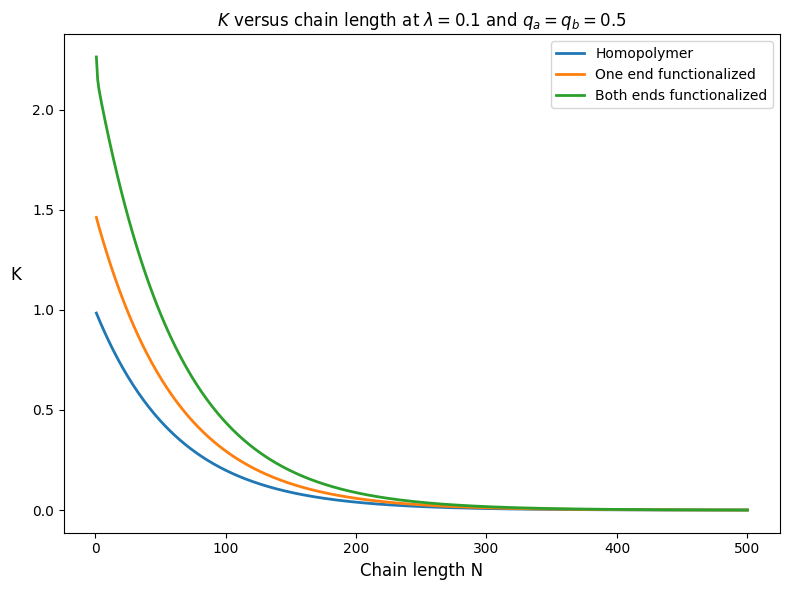

In [12]:
def chain_length_to_g(chain_length, b_over_pore_radius=1.0):
    """Convert ideal-chain length N to g=Rg/Rp."""
    return b_over_pore_radius * math.sqrt(chain_length / 6.0)

chain_lengths = list(range(1, 501))
b_over_pore_radius = 1.0
g_chain = [chain_length_to_g(n, b_over_pore_radius) for n in chain_lengths]

lambda_value = 0.1
homopolymer = [K_homopolymer(g, lambda_value) for g in g_chain]
single = [K_singly_functionalized(g, lambda_value, q_a) for g in g_chain]
double = [K_doubly_functionalized(g, lambda_value, q_a, q_b) for g in g_chain]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(chain_lengths, homopolymer, label="Homopolymer", linewidth=2)
ax.plot(chain_lengths, single, label="One end functionalized", linewidth=2)
ax.plot(chain_lengths, double, label="Both ends functionalized", linewidth=2)
ax.set_xlabel("Chain length N", fontsize=12)
ax.set_ylabel("K", fontsize=12, rotation=0, labelpad=12)
ax.set_title(r"$K$ versus chain length at $\lambda=0.1$ and $q_a=q_b=0.5$")
ax.legend()
ax.grid(False)
fig.tight_layout()
fig.savefig("singly_doubly_functionalized_K_vs_N.png", dpi=200, bbox_inches="tight")
plt.show()